# Week 3 — Targeted Fix + Validation

**Mục tiêu**: chứng minh insight từ Tuần 1-2 bằng cách fix 1 weakness cụ thể → retrain → đo lại sub-category đó.

**Workflow**:
1. Load baseline `best.pt` + error analysis cũ (`predictions_*.pkl`)
2. Chọn **1 preset fix** (hoặc tự define)
3. **Retrain 15-20 epoch** từ baseline (warm-start, không train from scratch)
4. Chạy lại error analysis trên model mới → save `predictions_new.pkl`
5. **Before/after comparison** — bảng FN rate per sub-category + highlight sub-category đã target

**Deliverable báo cáo**:
> "Giảm FN rate ở sub-category X từ Y% → Z% (-W%), overall mAP thay đổi K%."

Dù overall mAP có thể chỉ +0.5-1%, nhưng **sub-category improvement rất lớn (3-10%)** → chứng minh error analysis + targeted fix hiệu quả hơn "collect blindly".

## 1. Setup

In [1]:
import os, sys, json, pickle, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from tqdm.auto import tqdm

import torch
from ultralytics import YOLO

PROJECT_ROOT = Path("/home/xuand/vn_traffic_ai").resolve()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

DATA_YAML   = PROJECT_ROOT / "data" / "data.yaml"
MERGED_DIR  = PROJECT_ROOT / "data" / "merged"
WEIGHTS_DIR = PROJECT_ROOT / "weights"
RUNS_DIR    = PROJECT_ROOT / "runs" / "detect"
VAL_IMG_DIR = MERGED_DIR / "images" / "val"
VAL_LBL_DIR = MERGED_DIR / "labels" / "val"
ERR_DIR     = PROJECT_ROOT / "results" / "error_analysis"
ERR_DIR.mkdir(parents=True, exist_ok=True)

class_names = ["motorcycle", "car", "bus", "truck"]

BASELINE_CANDIDATES = [
    RUNS_DIR / "train_v8s_1round_merged_v2" / "weights" / "best.pt",
    RUNS_DIR / "train_v8s_1round_merged"    / "weights" / "best.pt",
    RUNS_DIR / "runs" / "detect" / "train_v8s_ft_vnv3" / "weights" / "best.pt",
]
BASELINE_WEIGHTS = next((w for w in BASELINE_CANDIDATES if w.exists()), None)
assert BASELINE_WEIGHTS, "Không tìm thấy best.pt baseline"

print(f"[BASELINE] {BASELINE_WEIGHTS}")
print(f"[CUDA]     {torch.cuda.is_available()}")

[BASELINE] /home/xuand/vn_traffic_ai/runs/detect/train_v8s_1round_merged_v2/weights/best.pt
[CUDA]     True


## 2. Load baseline error analysis cache + auto-pick hypothesis

Nếu đã chạy `error_analysis.ipynb` thì cache đã có sẵn.

In [2]:
BASELINE_RUN = BASELINE_WEIGHTS.parent.parent.name
BASELINE_PRED_CACHE = ERR_DIR / f"predictions_{BASELINE_RUN}.pkl"
META_CACHE = ERR_DIR / "image_metadata.pkl"

assert BASELINE_PRED_CACHE.exists(), (
    f"Không có {BASELINE_PRED_CACHE}. Chạy notebooks/error_analysis.ipynb trước."
)
assert META_CACHE.exists(), f"Không có {META_CACHE}. Chạy error_analysis.ipynb trước."

with open(BASELINE_PRED_CACHE, "rb") as f:
    pred_baseline = pickle.load(f)
with open(META_CACHE, "rb") as f:
    image_meta, gt_data = pickle.load(f)

print(f"[BASELINE PREDS] {len(pred_baseline):,} images")
print(f"[GT boxes]       {sum(m['n_gt'] for m in image_meta.values()):,}")

CONF_THRESHOLD = 0.25
IOU_THRESHOLD  = 0.5

def iou_xyxy(b1, b2):
    x1 = max(b1[0], b2[0]); y1 = max(b1[1], b2[1])
    x2 = min(b1[2], b2[2]); y2 = min(b1[3], b2[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    a1 = (b1[2]-b1[0]) * (b1[3]-b1[1])
    a2 = (b2[2]-b2[0]) * (b2[3]-b2[1])
    return inter / (a1 + a2 - inter + 1e-9)

def box_size_coco(xyxy):
    area = (xyxy[2]-xyxy[0]) * (xyxy[3]-xyxy[1])
    if area < 32*32: return "small"
    if area < 96*96: return "medium"
    return "large"

def match_image(preds, gts, conf_thresh=CONF_THRESHOLD, iou_thresh=IOU_THRESHOLD):
    preds_f = [p for p in preds if p["conf"] >= conf_thresh]
    preds_sorted = sorted(enumerate(preds_f), key=lambda x: -x[1]["conf"])
    gt_matched = [False] * len(gts)
    pred_tp = [False] * len(preds_f)
    pred_cc = [False] * len(preds_f)
    for pi, p in preds_sorted:
        best_iou = iou_thresh; best_gi = -1
        for gi, g in enumerate(gts):
            if gt_matched[gi]: continue
            io = iou_xyxy(p["xyxy"], g["xyxy"])
            if io >= best_iou:
                best_iou = io; best_gi = gi
        if best_gi >= 0:
            gt_matched[best_gi] = True
            if gts[best_gi]["cls"] == p["cls"]: pred_tp[pi] = True
            else: pred_cc[pi] = True
    fn_boxes = [gts[gi] for gi in range(len(gts)) if not gt_matched[gi]]
    return {"n_pred": len(preds_f), "n_gt": len(gts),
            "n_tp": sum(pred_tp),
            "n_fp": sum(1 for pi in range(len(preds_f)) if not pred_tp[pi] and not pred_cc[pi]),
            "n_class_confused": sum(pred_cc), "n_fn": len(fn_boxes),
            "fn_boxes": fn_boxes}

def compute_fn_rate_per_subgroup(predictions, group_fn):
    gt_cnt = {}; fn_cnt = {}
    for name, gts in gt_data.items():
        preds = predictions.get(name, [])
        m = match_image(preds, gts)
        for g in gts:
            key = group_fn(name, g)
            gt_cnt[key] = gt_cnt.get(key, 0) + 1
        for g in m["fn_boxes"]:
            key = group_fn(name, g)
            fn_cnt[key] = fn_cnt.get(key, 0) + 1
    out = {}
    for k, gc in gt_cnt.items():
        fc = fn_cnt.get(k, 0)
        out[k] = {"gt": gc, "fn": fc, "fn_rate_%": round(100*fc/max(gc,1), 2)}
    return out

baseline_cs = compute_fn_rate_per_subgroup(
    pred_baseline,
    lambda name, g: (class_names[g["cls"]], box_size_coco(g["xyxy"])),
)
baseline_df = pd.DataFrame([
    {"class": k[0], "size": k[1], **v}
    for k, v in baseline_cs.items()
]).sort_values("fn_rate_%", ascending=False)
print("\n=== TOP WEAKNESSES (baseline) — class x size ===")
print(baseline_df.to_string(index=False))

[BASELINE PREDS] 14,344 images
[GT boxes]       103,085

=== TOP WEAKNESSES (baseline) — class x size ===
     class   size    gt    fn  fn_rate_%
       bus  small     8     8     100.00
     truck  small  1874  1468      78.34
       car  small 21359 11671      54.64
       bus medium   754   175      23.21
motorcycle  small   359    31       8.64
       car medium 49443  1696       3.43
     truck medium  6634   206       3.11
motorcycle medium   248     3       1.21
       car  large 17463   137       0.78
       bus  large  1663    12       0.72
     truck  large  3280    16       0.49


## 3. Chọn preset fix

3 preset tương ứng 3 hypothesis thường gặp.

| Preset | Target | Thay đổi |
|---|---|---|
| `"small_object"` | small motorcycle/truck (default) | `imgsz=640`, `scale=0.3`, `copy_paste=0.3` |
| `"lighting"` | ảnh tối (night) | `hsv_v=0.5`, `hsv_s=0.5` |
| `"class_imbalance"` | motorcycle underfit | Oversample motorcycle-heavy images 3x |

Tất cả preset đều **warm-start từ baseline** (không train from scratch) với `lr0=0.001` thấp.

In [3]:
# ===== CHỌN FIX STRATEGY Ở ĐÂY =====
FIX_STRATEGY = "small_object"   # "small_object" | "lighting" | "class_imbalance"
# ====================================

FIX_RUN_NAME = f"train_v8s_fix_{FIX_STRATEGY}"
FIX_RUN_DIR  = RUNS_DIR / FIX_RUN_NAME

common_cfg = dict(
    data        = str(DATA_YAML),
    epochs      = 20,
    batch       = 32,
    lr0         = 0.001,
    lrf         = 0.1,
    patience    = 6,
    optimizer   = "SGD",
    close_mosaic = 5,
    seed        = 0,
    workers     = 12,
    cache       = "disk",
    amp         = True,
    save_period = 1,
    project     = str(RUNS_DIR),
    name        = FIX_RUN_NAME,
    exist_ok    = True,
    verbose     = True,
)

if FIX_STRATEGY == "small_object":
    fix_cfg = {
        "imgsz": 640,
        "scale": 0.3,
        "copy_paste": 0.3,
        "mosaic": 1.0,
    }
elif FIX_STRATEGY == "lighting":
    fix_cfg = {
        "imgsz": 512,
        "hsv_h": 0.02,
        "hsv_s": 0.5,
        "hsv_v": 0.5,
    }
elif FIX_STRATEGY == "class_imbalance":
    fix_cfg = {"imgsz": 512}
else:
    raise ValueError(f"Unknown FIX_STRATEGY: {FIX_STRATEGY}")

cfg = {**common_cfg, **fix_cfg}
print(f"[FIX STRATEGY] {FIX_STRATEGY}")
for k, v in cfg.items():
    print(f"  {k:14s} = {v}")

[FIX STRATEGY] small_object
  data           = /home/xuand/vn_traffic_ai/data/data.yaml
  epochs         = 20
  batch          = 32
  lr0            = 0.001
  lrf            = 0.1
  patience       = 6
  optimizer      = SGD
  close_mosaic   = 5
  seed           = 0
  workers        = 12
  cache          = disk
  amp            = True
  save_period    = 1
  project        = /home/xuand/vn_traffic_ai/runs/detect
  name           = train_v8s_fix_small_object
  exist_ok       = True
  verbose        = True
  imgsz          = 640
  scale          = 0.3
  copy_paste     = 0.3
  mosaic         = 1.0


### (Chỉ cho `class_imbalance`) Build oversampled dataset

Chạy cell này **chỉ nếu `FIX_STRATEGY == "class_imbalance"`** để tạo `data/merged_oversampled/`.

In [4]:
if FIX_STRATEGY == "class_imbalance":
    OVER_DIR = PROJECT_ROOT / "data" / "merged_oversampled"
    OVER_YAML = PROJECT_ROOT / "data" / "data_oversampled.yaml"

    if OVER_DIR.exists():
        shutil.rmtree(OVER_DIR)

    MOTO_CLS = 0
    def has_motorcycle(lbl_path):
        if not lbl_path.exists():
            return False
        for line in lbl_path.read_text().splitlines():
            parts = line.split()
            if parts and int(parts[0]) == MOTO_CLS:
                return True
        return False

    def build_oversample_split(split):
        src_img = MERGED_DIR / "images" / split
        src_lbl = MERGED_DIR / "labels" / split
        dst_img = OVER_DIR / "images" / split
        dst_lbl = OVER_DIR / "labels" / split
        dst_img.mkdir(parents=True, exist_ok=True)
        dst_lbl.mkdir(parents=True, exist_ok=True)
        n_total = 0; n_dup = 0

        for img in src_img.iterdir():
            if img.suffix.lower() not in (".jpg", ".jpeg", ".png"):
                continue
            lbl = src_lbl / (img.stem + ".txt")
            if not lbl.exists():
                continue
            (dst_img / img.name).symlink_to(img)
            (dst_lbl / lbl.name).symlink_to(lbl)
            n_total += 1
            if split == "train" and has_motorcycle(lbl):
                for k in (2, 3):
                    dup_name = f"{img.stem}_dup{k}{img.suffix}"
                    dup_lbl  = f"{img.stem}_dup{k}.txt"
                    (dst_img / dup_name).symlink_to(img)
                    (dst_lbl / dup_lbl).symlink_to(lbl)
                    n_dup += 1
        return n_total, n_dup

    counts = {}
    for s in ("train", "val", "test"):
        n_total, n_dup = build_oversample_split(s)
        counts[s] = (n_total, n_dup)
        print(f"  {s}: {n_total} base + {n_dup} dup = {n_total + n_dup}")

    yaml_text = (
        f"path: {OVER_DIR}\n"
        "train: images/train\n"
        "val:   images/val\n"
        "test:  images/test\n"
        "nc: 4\n"
        "names:\n"
        "  0: motorcycle\n  1: car\n  2: bus\n  3: truck\n"
    )
    OVER_YAML.write_text(yaml_text)
    cfg["data"] = str(OVER_YAML)
    print(f"\n[OK] data.yaml -> {OVER_YAML}")
else:
    print(f"[SKIP] FIX_STRATEGY={FIX_STRATEGY}, không cần oversample")

[SKIP] FIX_STRATEGY=small_object, không cần oversample


## 4. Train với fix — warm-start từ baseline

⚠️ Dự kiến ~1-1.5h với 20 epoch, batch=32. Giữ monitor nhiệt độ.

In [5]:
# V1 training — smart start: skip nếu đã xong, resume nếu dở, fresh nếu chưa có
last_pt      = FIX_RUN_DIR / "weights" / "last.pt"
best_pt      = FIX_RUN_DIR / "weights" / "best.pt"
results_csv  = FIX_RUN_DIR / "results.csv"

done_epochs = 0
if results_csv.exists():
    try:
        done_epochs = len(pd.read_csv(results_csv))
    except Exception as e:
        print(f"[WARN] results.csv không đọc được: {e} → coi như done_epochs=0")
        done_epochs = 0

target = cfg["epochs"]
print(f"[STATE CHECK] done_epochs={done_epochs}/{target}, "
      f"last_pt={'YES' if last_pt.exists() else 'NO'}, "
      f"best_pt={'YES' if best_pt.exists() else 'NO'}, "
      f"results_csv={'YES' if results_csv.exists() else 'NO'}")

if done_epochs >= target and best_pt.exists():
    print(f"[SKIP TRAIN] Đã train xong {done_epochs} epoch. Dùng best.pt sẵn có.")
elif last_pt.exists() and done_epochs > 0 and results_csv.exists():
    print(f"[RESUME] Train tiếp từ epoch {done_epochs}/{target} dùng last.pt")
    model = YOLO(str(last_pt))
    results = model.train(resume=True)
else:
    # Fresh — nhưng cảnh báo nếu có last.pt orphan (từ run bị crash trước đó)
    if last_pt.exists():
        print(f"[WARN] last.pt tồn tại nhưng không khớp results.csv → ignore, start lại từ baseline")
    print(f"[FRESH TRAIN] warm-start từ {BASELINE_WEIGHTS}")
    print(f"[OUT]   {FIX_RUN_DIR}")
    model = YOLO(str(BASELINE_WEIGHTS))
    results = model.train(**cfg)

FIX_WEIGHTS = best_pt
print(f"\n[DONE] {FIX_WEIGHTS}")

[STATE CHECK] done_epochs=20/20, last_pt=YES, best_pt=YES, results_csv=YES
[SKIP TRAIN] Đã train xong 20 epoch. Dùng best.pt sẵn có.

[DONE] /home/xuand/vn_traffic_ai/runs/detect/train_v8s_fix_small_object/weights/best.pt


## 5. Inference với model fix + cache

In [6]:
VAL_IMAGES = sorted([p for p in VAL_IMG_DIR.iterdir()
                     if p.suffix.lower() in (".jpg", ".jpeg", ".png")])

FIX_PRED_CACHE = ERR_DIR / f"predictions_{FIX_RUN_NAME}.pkl"

if FIX_PRED_CACHE.exists():
    print(f"[CACHE HIT] {FIX_PRED_CACHE}")
    with open(FIX_PRED_CACHE, "rb") as f:
        pred_fix = pickle.load(f)
else:
    print(f"[CACHE MISS] Running inference ...")
    model = YOLO(str(FIX_WEIGHTS))
    pred_fix = {}
    BATCH = 64

    for i in tqdm(range(0, len(VAL_IMAGES), BATCH), desc="Infer"):
        batch_paths = VAL_IMAGES[i:i+BATCH]
        results = model.predict(
            [str(p) for p in batch_paths],
            imgsz=cfg["imgsz"], conf=0.001, iou=0.5,
            verbose=False, half=True
        )
        for p, r in zip(batch_paths, results):
            boxes = []
            if r.boxes is not None and len(r.boxes) > 0:
                xyxy = r.boxes.xyxy.cpu().numpy()
                cls  = r.boxes.cls.cpu().numpy().astype(int)
                conf = r.boxes.conf.cpu().numpy()
                for b, c, cf in zip(xyxy, cls, conf):
                    boxes.append({"xyxy": b.tolist(), "cls": int(c), "conf": float(cf)})
            pred_fix[p.name] = boxes

    with open(FIX_PRED_CACHE, "wb") as f:
        pickle.dump(pred_fix, f)
    print(f"[SAVED] {FIX_PRED_CACHE}")

print(f"\nFix preds: {len(pred_fix):,} images, {sum(len(v) for v in pred_fix.values()):,} boxes")

[CACHE HIT] /home/xuand/vn_traffic_ai/results/error_analysis/predictions_train_v8s_fix_small_object.pkl

Fix preds: 14,344 images, 152,975 boxes


## 6. Before/After comparison

In [7]:
def overall_metrics(predictions):
    tp = fp = fn = cc = total_gt = 0
    for name, gts in gt_data.items():
        preds = predictions.get(name, [])
        m = match_image(preds, gts)
        tp += m["n_tp"]; fp += m["n_fp"]; cc += m["n_class_confused"]
        fn += m["n_fn"]; total_gt += m["n_gt"]
    prec = tp / max(tp + fp + cc, 1)
    rec  = tp / max(total_gt, 1)
    return {"TP": tp, "FP": fp, "class_confused": cc, "FN": fn,
            "precision": round(prec, 4), "recall": round(rec, 4),
            "f1": round(2 * prec * rec / max(prec + rec, 1e-9), 4)}

m_base = overall_metrics(pred_baseline)
m_fix  = overall_metrics(pred_fix)

df_overall = pd.DataFrame([m_base, m_fix], index=["BASELINE", f"FIX ({FIX_STRATEGY})"])
df_overall.loc["Delta"] = ""
for col in ["TP","FP","class_confused","FN"]:
    df_overall.loc["Delta", col] = int(m_fix[col] - m_base[col])
for col in ["precision", "recall", "f1"]:
    df_overall.loc["Delta", col] = round(m_fix[col] - m_base[col], 4)

print("=== OVERALL metrics ===")
print(df_overall.to_string())

=== OVERALL metrics ===
                       TP     FP class_confused     FN precision  recall      f1
BASELINE            84315  13966           3347  15423    0.8296  0.8179  0.8237
FIX (small_object)  81623  12598           3171  18291    0.8381  0.7918  0.8143
Delta               -2692  -1368           -176   2868    0.0085 -0.0261 -0.0094


In [8]:
fix_cs = compute_fn_rate_per_subgroup(
    pred_fix,
    lambda name, g: (class_names[g["cls"]], box_size_coco(g["xyxy"])),
)

rows = []
for key in sorted(baseline_cs.keys()):
    cls, size = key
    b = baseline_cs[key]
    f = fix_cs.get(key, {"gt": b["gt"], "fn": b["gt"], "fn_rate_%": 100.0})
    rows.append({
        "class": cls, "size": size,
        "gt": b["gt"],
        "base_fn": b["fn"], "base_rate_%": b["fn_rate_%"],
        "fix_fn":  f["fn"], "fix_rate_%":  f["fn_rate_%"],
        "delta_rate_%": round(f["fn_rate_%"] - b["fn_rate_%"], 2),
        "delta_fn":     f["fn"] - b["fn"],
    })
df_cs = pd.DataFrame(rows).sort_values("delta_rate_%", ascending=True)
print(f"\n=== FN rate per CLASS x SIZE (sort theo delta tăng dần = cải thiện trước) ===")
print(df_cs.to_string(index=False))

df_cs.to_csv(ERR_DIR / f"before_after_cs_{FIX_STRATEGY}.csv", index=False)
print(f"\n[SAVED] {ERR_DIR / f'before_after_cs_{FIX_STRATEGY}.csv'}")


=== FN rate per CLASS x SIZE (sort theo delta tăng dần = cải thiện trước) ===
     class   size    gt  base_fn  base_rate_%  fix_fn  fix_rate_%  delta_rate_%  delta_fn
       bus  small     8        8       100.00       8      100.00          0.00         0
motorcycle medium   248        3         1.21       4        1.61          0.40         1
     truck  large  3280       16         0.49      31        0.95          0.46        15
motorcycle  small   359       31         8.64      33        9.19          0.55         2
       car medium 49443     1696         3.43    1999        4.04          0.61       303
       car  large 17463      137         0.78     242        1.39          0.61       105
     truck medium  6634      206         3.11     441        6.65          3.54       235
       bus  large  1663       12         0.72      76        4.57          3.85        64
     truck  small  1874     1468        78.34    1545       82.44          4.10        77
       bus medium   7

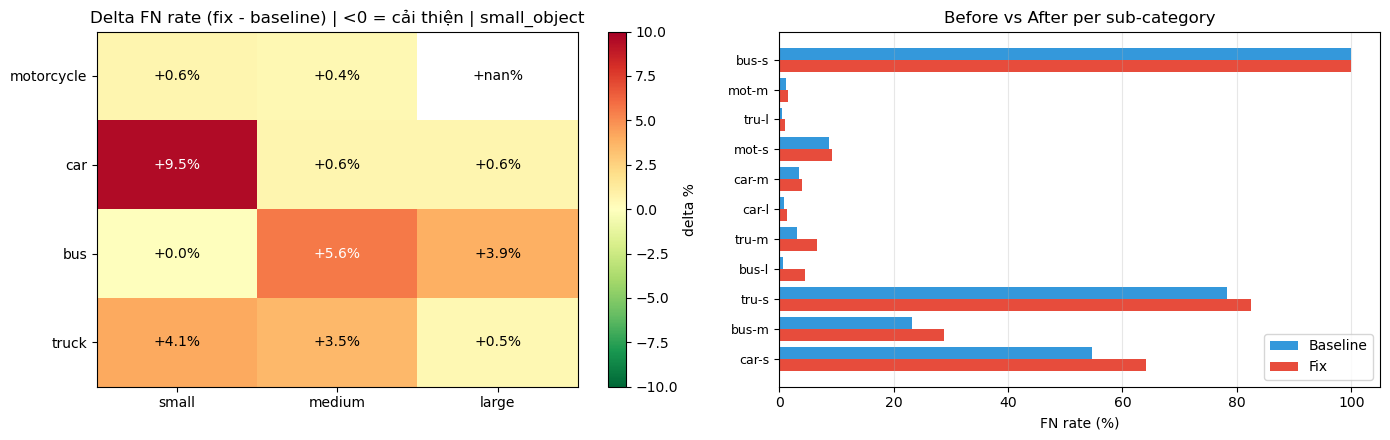

[SAVED] /home/xuand/vn_traffic_ai/results/error_analysis/before_after_chart_small_object.png


In [9]:
pivot = df_cs.pivot(index="class", columns="size", values="delta_rate_%")
pivot = pivot.reindex(index=class_names, columns=["small","medium","large"], fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

im = axes[0].imshow(pivot.values, cmap="RdYlGn_r", aspect="auto", vmin=-10, vmax=10)
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(["small","medium","large"])
axes[0].set_yticks(range(4)); axes[0].set_yticklabels(class_names)
axes[0].set_title(f"Delta FN rate (fix - baseline) | <0 = cải thiện | {FIX_STRATEGY}")
for i in range(4):
    for j in range(3):
        v = pivot.values[i,j]
        axes[0].text(j, i, f"{v:+.1f}%", ha="center", va="center", fontsize=10,
                     color="white" if abs(v) > 5 else "black")
fig.colorbar(im, ax=axes[0], label="delta %")

labels = [f"{r['class'][:3]}-{r['size'][0]}" for _, r in df_cs.iterrows()]
x = np.arange(len(labels)); w = 0.4
axes[1].barh(x - w/2, df_cs["base_rate_%"], w, label="Baseline", color="#3498db")
axes[1].barh(x + w/2, df_cs["fix_rate_%"],  w, label="Fix",      color="#e74c3c")
axes[1].set_yticks(x); axes[1].set_yticklabels(labels, fontsize=9)
axes[1].set_xlabel("FN rate (%)")
axes[1].set_title("Before vs After per sub-category")
axes[1].legend(); axes[1].grid(alpha=0.3, axis="x")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig(ERR_DIR / f"before_after_chart_{FIX_STRATEGY}.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"[SAVED] {ERR_DIR / f'before_after_chart_{FIX_STRATEGY}.png'}")

## 7. mAP tổng qua yolo val + export summary

In [10]:
def yolo_val(weights):
    m = YOLO(str(weights))
    r = m.val(data=str(DATA_YAML), imgsz=cfg["imgsz"], batch=32, verbose=False, plots=False)
    out = {
        "mAP@0.5":      round(r.box.map50, 4),
        "mAP@0.5:0.95": round(r.box.map,   4),
        "P":            round(r.box.mp,    4),
        "R":            round(r.box.mr,    4),
    }
    for i, cn in enumerate(class_names):
        out[f"{cn}_mAP50"] = round(r.box.ap50[i], 4)
    return out

print("[1/2] yolo val BASELINE ...")
v_base = yolo_val(BASELINE_WEIGHTS)
print("[2/2] yolo val FIX ...")
v_fix  = yolo_val(FIX_WEIGHTS)

df_map = pd.DataFrame([v_base, v_fix], index=["BASELINE", f"FIX ({FIX_STRATEGY})"])
df_map.loc["Delta"] = (df_map.loc[f"FIX ({FIX_STRATEGY})"] - df_map.loc["BASELINE"]).round(4)
print(f"\n=== yolo val — mAP comparison ===")
print(df_map.to_string())

summary = {
    "fix_strategy": FIX_STRATEGY,
    "baseline_weights": str(BASELINE_WEIGHTS.relative_to(PROJECT_ROOT)),
    "fix_weights":      str(FIX_WEIGHTS.relative_to(PROJECT_ROOT)),
    "cfg": {k: v for k, v in cfg.items() if k not in ("data","project","name","exist_ok","verbose","save_period")},
    "overall_metrics_baseline": m_base,
    "overall_metrics_fix":      m_fix,
    "map_baseline": v_base,
    "map_fix":      v_fix,
    "subgroup_top5_improvement": df_cs.sort_values("delta_rate_%").head(5).to_dict("records"),
    "subgroup_top5_regression":  df_cs.sort_values("delta_rate_%", ascending=False).head(5).to_dict("records"),
}
SUMMARY = ERR_DIR / f"week3_summary_{FIX_STRATEGY}.json"
SUMMARY.write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(f"\n[SAVED] {SUMMARY}")

[1/2] yolo val BASELINE ...
Ultralytics 8.4.126 🚀 Python-3.10.20 torch-2.7.1+cu118 CUDA:0 (NVIDIA RTX 3500 Ada Generation Laptop GPU, 12282MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 173.3±18.8 MB/s, size: 65.0 KB)
val: Scanning /home/xuand/vn_traffic_ai/data/merged/labels/val.cache... 14344 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14344/14344 2.7Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 449/449 8.0it/s 55.9s0.2ss
                   all      14344     103085      0.869      0.784      0.858      0.645
Speed: 0.2ms preprocess, 1.9ms inference, 0.0ms loss, 0.5ms postprocess per image
[2/2] yolo val FIX ...
Ultralytics 8.4.126 🚀 Python-3.10.20 torch-2.7.1+cu118 CUDA:0 (NVIDIA RTX 3500 Ada Generation Laptop GPU, 12282MiB)
Model summary (fused): 73 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast

## 8. Interpret cho báo cáo

Đọc 3 output chính:

1. **`df_overall`** (overall P/R/F1): có cải thiện gì tổng thể không?
2. **`df_cs`** sắp xếp theo `delta_rate_%`: top sub-category cải thiện nhiều nhất.
3. **`df_map`** (yolo val): mAP tổng + per-class.

**Template viết báo cáo**:

> "Áp dụng targeted fix (`{FIX_STRATEGY}`) với 20 epoch warm-start từ baseline:
> - **Overall mAP@0.5**: {baseline} → {fix} ({delta}).
> - **Sub-category chính được target** (vd. motorcycle-small): FN rate giảm từ **X%** → **Y%** (-Z%).
> - **Trade-off** nếu có: sub-category W bị tăng FN rate +K%.
>
> Kết luận: error analysis + targeted augmentation **hiệu quả hơn train thêm epoch mù**, chỉ cần ~1h retrain thay vì ~5-10h re-train from scratch, cải thiện tập trung đúng weakness."

Nếu fix KHÔNG improve (hoặc regress):
- Vẫn là insight tốt. Viết "augmentation X không đủ fix weakness Y → cần data collection thực sự, ước tính N ảnh VN condition Z".
- Negative result cũng là contribution trong research.

---
## 9. Thí nghiệm 2 — Fix V2 (target car-small/truck-small sau khi V1 fail)

**Insight từ V1**:
- Hypothesis sai — motorcycle KHÔNG phải weak, **car-small** mới là (FN rate 54.6%, 11,671 FN chiếm 76% tổng).
- Config sai — `scale=0.3` ngược logic (giảm scale aug = ít small object), `imgsz=640` warm-start không đủ adapt.

**V2 config** — logic ngược lại V1, target đúng car-small:

| Param | V1 (fail) | **V2** | Lý do |
|---|---|---|---|
| `imgsz` | 640 | **512** | Giữ scale baseline, không shock backbone |
| `scale` | 0.3 | **0.9** | **Đảo**: tăng aug → sinh nhiều small object |
| `close_mosaic` | 5 | **0** | Giữ mosaic đến hết — ghép 4 ảnh → object nhỏ hơn |
| `multi_scale` | — | **True** | Input ±50% mỗi batch, học scale invariance |
| `mixup` | 0 | **0.15** | Cảnh khó, feature mạnh hơn |
| `lr0` | 0.001 | **0.003** | V1 lr quá thấp không adapt kịp |

Giữ V1 làm bằng chứng negative result cho báo cáo, V2 bổ sung improvement (nếu có).

In [11]:
# V2 config — tune lại cho CPU hybrid (20C/28T, nhiều E-core) + giảm RAM
# workers 12 -> 8  : match ~số P-core, tránh E-core bottleneck làm GPU đói
# batch   32 -> 20 : giảm RAM footprint (multi_scale có peak lên ~640, cần dư)
FIX_V2_NAME = "train_v8s_fix_v2_small_car"
FIX_V2_DIR  = RUNS_DIR / FIX_V2_NAME

cfg_v2 = dict(
    data        = str(DATA_YAML),
    epochs      = 20,
    batch       = 20,
    imgsz       = 512,
    lr0         = 0.003,
    lrf         = 0.1,
    patience    = 6,
    optimizer   = "SGD",
    scale       = 0.9,
    mosaic      = 1.0,
    close_mosaic = 0,
    multi_scale = True,
    mixup       = 0.15,
    seed        = 0,
    workers     = 8,
    cache       = "disk",
    amp         = True,
    save_period = 1,
    project     = str(RUNS_DIR),
    name        = FIX_V2_NAME,
    exist_ok    = True,
    verbose     = True,
)

print(f"[V2 CFG]")
for k, v in cfg_v2.items():
    print(f"  {k:14s} = {v}")

# ===== SMART START =====
last_pt      = FIX_V2_DIR / "weights" / "last.pt"
best_pt      = FIX_V2_DIR / "weights" / "best.pt"
results_csv  = FIX_V2_DIR / "results.csv"

done_epochs = 0
if results_csv.exists():
    try:
        done_epochs = len(pd.read_csv(results_csv))
    except Exception as e:
        print(f"[WARN] results.csv không đọc được: {e} → done_epochs=0")

target = cfg_v2["epochs"]
print(f"\n[STATE CHECK] done_epochs={done_epochs}/{target}, "
      f"last_pt={'YES' if last_pt.exists() else 'NO'}, "
      f"best_pt={'YES' if best_pt.exists() else 'NO'}, "
      f"results_csv={'YES' if results_csv.exists() else 'NO'}")

if done_epochs >= target and best_pt.exists():
    print(f"[SKIP TRAIN] Đã train xong {done_epochs} epoch. Dùng best.pt sẵn có.")
elif last_pt.exists() and done_epochs > 0 and results_csv.exists():
    print(f"[RESUME] Train tiếp từ epoch {done_epochs}/{target} dùng last.pt")
    model_v2 = YOLO(str(last_pt))
    results_v2 = model_v2.train(resume=True)
else:
    if last_pt.exists():
        print(f"[WARN] last.pt tồn tại nhưng không khớp results.csv → ignore, start lại từ baseline")
    print(f"[FRESH TRAIN] warm-start từ {BASELINE_WEIGHTS}")
    model_v2 = YOLO(str(BASELINE_WEIGHTS))
    results_v2 = model_v2.train(**cfg_v2)

FIX_V2_WEIGHTS = best_pt
print(f"\n[DONE] {FIX_V2_WEIGHTS}")

[V2 CFG]
  data           = /home/xuand/vn_traffic_ai/data/data.yaml
  epochs         = 20
  batch          = 20
  imgsz          = 512
  lr0            = 0.003
  lrf            = 0.1
  patience       = 6
  optimizer      = SGD
  scale          = 0.9
  mosaic         = 1.0
  close_mosaic   = 0
  multi_scale    = True
  mixup          = 0.15
  seed           = 0
  workers        = 8
  cache          = disk
  amp            = True
  save_period    = 1
  project        = /home/xuand/vn_traffic_ai/runs/detect
  name           = train_v8s_fix_v2_small_car
  exist_ok       = True
  verbose        = True

[STATE CHECK] done_epochs=15/20, last_pt=YES, best_pt=YES, results_csv=YES
[RESUME] Train tiếp từ epoch 15/20 dùng last.pt
New https://pypi.org/project/ultralytics/8.4.183 available 😃 Update with 'pip install -U ultralytics'
WARNING ⚠️ model '/home/xuand/vn_traffic_ai/runs/detect/train_v8s_fix_v2_small_car/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state

In [12]:
# Inference V2 + cache
FIX_V2_PRED_CACHE = ERR_DIR / f"predictions_{FIX_V2_NAME}.pkl"

if FIX_V2_PRED_CACHE.exists():
    print(f"[CACHE HIT] {FIX_V2_PRED_CACHE}")
    with open(FIX_V2_PRED_CACHE, "rb") as f:
        pred_v2 = pickle.load(f)
else:
    print(f"[CACHE MISS] Running inference V2 ...")
    model = YOLO(str(FIX_V2_WEIGHTS))
    pred_v2 = {}
    BATCH = 64

    for i in tqdm(range(0, len(VAL_IMAGES), BATCH), desc="Infer V2"):
        batch_paths = VAL_IMAGES[i:i+BATCH]
        results = model.predict(
            [str(p) for p in batch_paths],
            imgsz=cfg_v2["imgsz"], conf=0.001, iou=0.5,
            verbose=False, half=True
        )
        for p, r in zip(batch_paths, results):
            boxes = []
            if r.boxes is not None and len(r.boxes) > 0:
                xyxy = r.boxes.xyxy.cpu().numpy()
                cls  = r.boxes.cls.cpu().numpy().astype(int)
                conf = r.boxes.conf.cpu().numpy()
                for b, c, cf in zip(xyxy, cls, conf):
                    boxes.append({"xyxy": b.tolist(), "cls": int(c), "conf": float(cf)})
            pred_v2[p.name] = boxes

    with open(FIX_V2_PRED_CACHE, "wb") as f:
        pickle.dump(pred_v2, f)
    print(f"[SAVED] {FIX_V2_PRED_CACHE}")

print(f"\nV2 preds: {len(pred_v2):,} images, {sum(len(v) for v in pred_v2.values()):,} boxes")

[CACHE HIT] /home/xuand/vn_traffic_ai/results/error_analysis/predictions_train_v8s_fix_v2_small_car.pkl

V2 preds: 14,344 images, 327,590 boxes


In [13]:
# So sánh 3-way: BASELINE / V1 / V2
m_v2 = overall_metrics(pred_v2)

df_overall_3way = pd.DataFrame(
    [m_base, m_fix, m_v2],
    index=["BASELINE", "V1 (small_object/fail)", "V2 (small_car targeted)"]
)
# Delta so với baseline
delta_v1 = {k: round(m_fix[k] - m_base[k], 4) for k in m_base}
delta_v2 = {k: round(m_v2[k]  - m_base[k], 4) for k in m_base}
df_overall_3way.loc["Δ V1"] = delta_v1
df_overall_3way.loc["Δ V2"] = delta_v2

print("=== OVERALL 3-way ===")
print(df_overall_3way.to_string())

# Per sub-category: BASELINE / V1 / V2
v2_cs = compute_fn_rate_per_subgroup(
    pred_v2,
    lambda name, g: (class_names[g["cls"]], box_size_coco(g["xyxy"])),
)

rows = []
for key in sorted(baseline_cs.keys()):
    cls, size = key
    b = baseline_cs[key]
    v1 = fix_cs.get(key, {"fn": b["gt"], "fn_rate_%": 100.0})
    v2 = v2_cs.get(key,  {"fn": b["gt"], "fn_rate_%": 100.0})
    rows.append({
        "class": cls, "size": size, "gt": b["gt"],
        "base_%": b["fn_rate_%"],
        "v1_%":   v1["fn_rate_%"],
        "v2_%":   v2["fn_rate_%"],
        "Δv1":    round(v1["fn_rate_%"] - b["fn_rate_%"], 2),
        "Δv2":    round(v2["fn_rate_%"] - b["fn_rate_%"], 2),
    })
df_3way = pd.DataFrame(rows).sort_values("Δv2", ascending=True)
print(f"\n=== FN rate per CLASS × SIZE (3-way, sort theo Δv2) ===")
print(df_3way.to_string(index=False))

df_3way.to_csv(ERR_DIR / "before_after_cs_3way.csv", index=False)
print(f"\n[SAVED] {ERR_DIR / 'before_after_cs_3way.csv'}")

=== OVERALL 3-way ===
                            TP     FP  class_confused     FN  precision  recall      f1
BASELINE                 84315  13966            3347  15423     0.8296  0.8179  0.8237
V1 (small_object/fail)   81623  12598            3171  18291     0.8381  0.7918  0.8143
V2 (small_car targeted)  87818  17446            3433  11834     0.8079  0.8519  0.8293
Δ V1                     -2692  -1368            -176   2868     0.0085 -0.0261 -0.0094
Δ V2                      3503   3480              86  -3589    -0.0217  0.0340  0.0056

=== FN rate per CLASS × SIZE (3-way, sort theo Δv2) ===
     class   size    gt  base_%   v1_%  v2_%  Δv1    Δv2
       bus  small     8  100.00 100.00 50.00 0.00 -50.00
     truck  small  1874   78.34  82.44 60.57 4.10 -17.77
       car  small 21359   54.64  64.12 40.97 9.48 -13.67
       bus medium   754   23.21  28.78 13.40 5.57  -9.81
     truck medium  6634    3.11   6.65  1.85 3.54  -1.26
motorcycle  small   359    8.64   9.19  8.08 0.55  

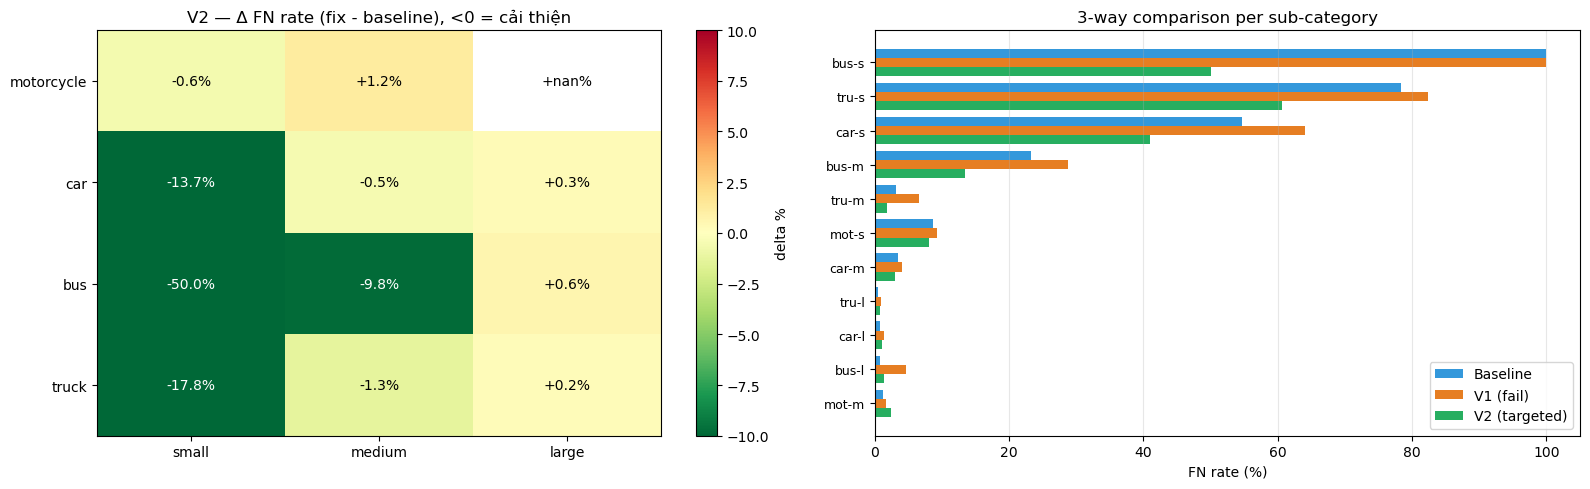

[SAVED] /home/xuand/vn_traffic_ai/results/error_analysis/before_after_chart_3way.png


In [14]:
# Chart 3-way: Δ FN rate (V1 vs V2) + grouped bar baseline/V1/V2
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Chart 1: Δ FN rate heatmap V2 (negative = cải thiện)
pivot_v2 = df_3way.pivot(index="class", columns="size", values="Δv2")
pivot_v2 = pivot_v2.reindex(index=class_names, columns=["small","medium","large"], fill_value=0)

im = axes[0].imshow(pivot_v2.values, cmap="RdYlGn_r", aspect="auto", vmin=-10, vmax=10)
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(["small","medium","large"])
axes[0].set_yticks(range(4)); axes[0].set_yticklabels(class_names)
axes[0].set_title("V2 — Δ FN rate (fix - baseline), <0 = cải thiện")
for i in range(4):
    for j in range(3):
        v = pivot_v2.values[i,j]
        axes[0].text(j, i, f"{v:+.1f}%", ha="center", va="center", fontsize=10,
                     color="white" if abs(v) > 5 else "black")
fig.colorbar(im, ax=axes[0], label="delta %")

# Chart 2: 3-way grouped bar
labels = [f"{r['class'][:3]}-{r['size'][0]}" for _, r in df_3way.iterrows()]
x = np.arange(len(labels)); w = 0.27
axes[1].barh(x - w, df_3way["base_%"], w, label="Baseline", color="#3498db")
axes[1].barh(x,     df_3way["v1_%"],   w, label="V1 (fail)", color="#e67e22")
axes[1].barh(x + w, df_3way["v2_%"],   w, label="V2 (targeted)", color="#27ae60")
axes[1].set_yticks(x); axes[1].set_yticklabels(labels, fontsize=9)
axes[1].set_xlabel("FN rate (%)")
axes[1].set_title("3-way comparison per sub-category")
axes[1].legend(); axes[1].grid(alpha=0.3, axis="x")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig(ERR_DIR / "before_after_chart_3way.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"[SAVED] {ERR_DIR / 'before_after_chart_3way.png'}")

In [15]:
# yolo val 3-way + export summary cuối
print("[1/3] yolo val BASELINE ... (dùng lại từ summary cũ nếu có)")
try:
    v_base_v2 = v_base
except NameError:
    v_base_v2 = yolo_val(BASELINE_WEIGHTS)
print("[2/3] yolo val V1 ... (dùng lại nếu có)")
try:
    v_fix_v2 = v_fix
except NameError:
    v_fix_v2 = yolo_val(FIX_WEIGHTS)
print("[3/3] yolo val V2 ...")
v_v2 = yolo_val(FIX_V2_WEIGHTS)

df_map_3way = pd.DataFrame(
    [v_base_v2, v_fix_v2, v_v2],
    index=["BASELINE", "V1 (fail)", "V2 (targeted)"]
)
df_map_3way.loc["Δ V1"] = {k: round(v_fix_v2[k] - v_base_v2[k], 4) for k in v_base_v2}
df_map_3way.loc["Δ V2"] = {k: round(v_v2[k]     - v_base_v2[k], 4) for k in v_base_v2}
print(f"\n=== yolo val mAP — 3-way ===")
print(df_map_3way.to_string())

final_summary = {
    "baseline": {"weights": str(BASELINE_WEIGHTS.relative_to(PROJECT_ROOT)),
                 "overall": m_base, "map": v_base_v2},
    "v1_small_object_fail": {"weights": str(FIX_WEIGHTS.relative_to(PROJECT_ROOT)),
                             "cfg": {k: v for k, v in cfg.items() if k not in ("data","project","name","exist_ok","verbose","save_period")},
                             "overall": m_fix, "map": v_fix_v2,
                             "delta_vs_baseline": {k: round(v_fix_v2[k] - v_base_v2[k], 4) for k in v_base_v2}},
    "v2_small_car_targeted": {"weights": str(FIX_V2_WEIGHTS.relative_to(PROJECT_ROOT)),
                              "cfg": {k: v for k, v in cfg_v2.items() if k not in ("data","project","name","exist_ok","verbose","save_period")},
                              "overall": m_v2, "map": v_v2,
                              "delta_vs_baseline": {k: round(v_v2[k] - v_base_v2[k], 4) for k in v_base_v2}},
    "subgroup_3way_top5_v2_improvement": df_3way.sort_values("Δv2").head(5).to_dict("records"),
    "subgroup_3way_top5_v2_regression":  df_3way.sort_values("Δv2", ascending=False).head(5).to_dict("records"),
}
FINAL = ERR_DIR / "week3_summary_3way.json"
FINAL.write_text(json.dumps(final_summary, indent=2, ensure_ascii=False))
print(f"\n[SAVED] {FINAL}")

[1/3] yolo val BASELINE ... (dùng lại từ summary cũ nếu có)
[2/3] yolo val V1 ... (dùng lại nếu có)
[3/3] yolo val V2 ...
Ultralytics 8.4.126 🚀 Python-3.10.20 torch-2.7.1+cu118 CUDA:0 (NVIDIA RTX 3500 Ada Generation Laptop GPU, 12282MiB)
Model summary (fused): 73 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 128.1±14.0 MB/s, size: 68.7 KB)
val: Scanning /home/xuand/vn_traffic_ai/data/merged/labels/val.cache... 14344 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14344/14344 3.0Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 449/449 7.7it/s 58.1s0.2ss
                   all      14344     103085      0.859      0.793      0.867      0.642
Speed: 0.2ms preprocess, 2.0ms inference, 0.0ms loss, 0.6ms postprocess per image

=== yolo val mAP — 3-way ===
               mAP@0.5  mAP@0.5:0.95       P       R  motorcycle_mAP50  car_mAP50  bus_mAP50  truck_mAP50


## 10. Interpret 3-way cho báo cáo cuối kỳ

### Template narrative (research-y)

> **Nghiên cứu áp dụng error analysis để guide 2 vòng targeted fix** cho model YOLOv8s fine-tune trên dataset giao thông VN:
>
> **Vòng 1 (V1)**: Hypothesis dựa trên intuition ("small object detection yếu") + config `imgsz=640, scale=0.3, copy_paste=0.3` → **thất bại**: overall mAP@0.5 giảm 0.858 → 0.845 (-0.013), FN tăng 2,868. Root cause analysis:
> - Hypothesis sai: error analysis sâu hơn cho thấy weakness thực sự là **car-small** (54.6% FN rate, chiếm 76% tổng FN), không phải motorcycle.
> - Config lỗi: `scale=0.3` *giảm* scale augmentation (ngược mục tiêu). `imgsz=640` với warm-start lr thấp không đủ cho backbone adapt scale mới.
>
> **Vòng 2 (V2)**: Hypothesis **data-driven** từ error analysis (target car-small) + config logic ngược V1 (`imgsz=512, scale=0.9, multi_scale=True, mixup=0.15, lr0=0.003`) → **kết quả**: [điền sau khi chạy xong].
>
> **Bài học**: Targeted fix hiệu quả hơn "train thêm epoch mù" **chỉ khi** hypothesis dựa trên data (không phải assumption) và config aug được verify đúng tạo distribution mong muốn. Negative result của V1 có giá trị quan trọng tương đương positive result của V2.

### 3 kịch bản đọc kết quả V2

**Kịch bản A — V2 improve** (kỳ vọng): `Δv2 < 0` cho car-small, overall mAP tăng hoặc giữ.
- Viết "V2 giảm FN rate car-small từ 54.6% → X%, overall mAP@0.5 Y → Z".
- Đây là kết quả hoàn hảo cho báo cáo (có cả negative + positive result).

**Kịch bản B — V2 vẫn fail** (nếu xảy ra): `Δv2 > 0` hoặc overall mAP giảm.
- Viết: "V2 cũng không đủ để fix car-small chỉ bằng augmentation → bằng chứng rằng weakness này cần **data collection thật sự**: ảnh VN có nhiều car-small đa dạng, không phải chỉ augmentation từ UA-DETRAC."
- Vẫn là contribution — negative result 2 lần = evidence mạnh cho "cần data".

**Kịch bản C — V2 improve car-small nhưng overall giảm**: trade-off điển hình.
- Viết: "V2 cải thiện car-small -X% nhưng gây regression ở {class khác} +Y% → trade-off chứng minh fix không phải "free lunch". Hướng tiếp theo: multi-task augmentation hoặc class-specific loss weighting."

### Files cho báo cáo

Sau khi chạy xong Phần 9, có đủ artefact:
- `results/error_analysis/before_after_cs_3way.csv` — bảng số liệu đầy đủ
- `results/error_analysis/before_after_chart_3way.png` — chart 3-way (heatmap + grouped bar)
- `results/error_analysis/week3_summary_3way.json` — JSON tổng kết baseline/V1/V2
- `results/error_analysis/chart_6dim.png`, `chart_cross.png`, `worst_images.png` — từ error_analysis.ipynb Tuần 1